In [14]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [15]:
data = yf.download('BTC-USD','2015-01-01','2023-11-30')

/tmp/ipykernel_2522/3540120103.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('BTC-USD','2015-01-01','2023-11-30')
[*********************100%***********************]  1 of 1 completed


In [16]:
data = pd.DataFrame(data)

In [17]:
data.reset_index(inplace=True)

In [18]:
# Flatten the MultiIndex columns by keeping only the metric name (e.g., 'Close')
data.columns = data.columns.get_level_values(0)

# Drop the unnecessary columns (note: 'Adj Close' is not in this dataset, so we omit it)
data.drop(columns=['Date', 'Open', 'High', 'Low', 'Volume'], inplace=True)

In [19]:
data

Price,Close
0,314.248993
1,315.032013
2,281.082001
3,264.195007
4,274.473999
...,...
3250,37796.792969
3251,37479.121094
3252,37254.167969
3253,37831.085938


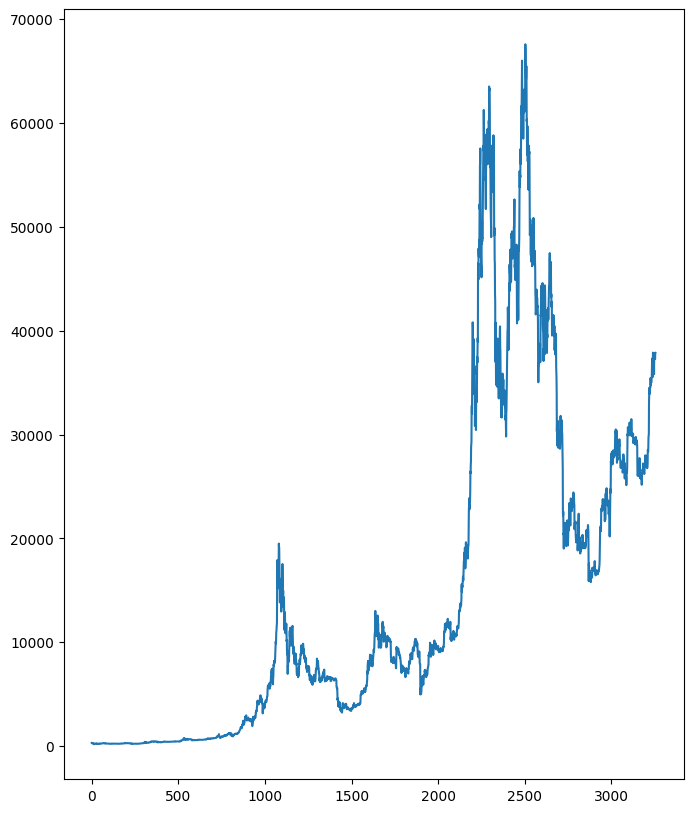

In [20]:
plt.figure(figsize=(8,10))
plt.plot(data)
plt.show()

In [21]:
train_data = data[:-100]
test_data = data[-100:]

In [22]:
train_data.shape

(3155, 1)

In [23]:
test_data.shape

(100, 1)

In [24]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

In [25]:
train_data_scale = scaler.fit_transform(train_data)

In [26]:
base_days = 100

In [27]:
x = []
y = []
for i in range(base_days, train_data_scale.shape[0]):
    x.append(train_data_scale[i-base_days:i])
    y.append(train_data_scale[i,0])

In [28]:
x, y = np.array(x), np.array(y)

In [29]:
x = np.reshape(x, (x.shape[0],x.shape[1],1))

In [30]:
from keras.layers import LSTM, Dense, Dropout
from keras.models import Sequential

In [31]:
model = Sequential()
model.add(LSTM(50, activation = 'relu', return_sequences=True, input_shape=(x.shape[1],1)))
model.add(Dropout(0.2))
model.add(LSTM(60, activation='relu',return_sequences=True))
model.add(Dropout(0.3))
model.add(LSTM(80, activation='relu',return_sequences=True))
model.add(Dropout(0.4))
model.add(LSTM(120, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(units=1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [32]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 60)        │        26,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 60)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 100, 80)        │        45,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100, 80)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 120)            │        96,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,761 (698.29 KB)

 Trainable params: 178,761 (698.29 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
model.compile(optimizer='adam', loss = 'mean_squared_error')

In [34]:
model.fit(x, y, epochs = 50, verbose =1 )

Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 34s 292ms/step - loss: 0.0159
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 41s 290ms/step - loss: 0.0049
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 40s 285ms/step - loss: 0.0039
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 41s 285ms/step - loss: 0.0045
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 27s 285ms/step - loss: 0.0040
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 41s 286ms/step - loss: 0.0040
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 28s 286ms/step - loss: 0.0032
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 28s 285ms/step - loss: 0.0032
Epoch 9/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 27s 286ms/step - loss: 0.0031
Epoch 10/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 27s 284ms/step - loss: 0.0033
Epoch 11/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 41s 285ms/step - loss: 0.0027
Epoch 12/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 28s 297ms/step - loss: 0.0029
Epoch 13/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 40s 287ms/step - loss: 0.0026
Epoch 14/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 27s 285ms/step - loss: 0.0028
Epoch 15/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 27s 

In [35]:
test_data = pd.concat((train_data.tail(100), test_data), ignore_index=True)

In [36]:
test_data

Price,Close
0,26930.638672
1,27192.693359
2,27036.650391
3,27398.802734
4,26832.208984
...,...
195,37796.792969
196,37479.121094
197,37254.167969
198,37831.085938


In [37]:
test_data_scale = scaler.transform(test_data)

In [38]:
x = []
y = []

for i in range(base_days, test_data_scale.shape[0]):
    x.append(test_data_scale[i-base_days:i])
    y.append(test_data_scale[i,0])

In [39]:
x, y = np.array(x), np.array(y)

In [40]:
x = np.reshape(x, (x.shape[0],x.shape[1],1))

In [41]:
pred = model.predict(x)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 220ms/step


In [42]:
pred = scaler.inverse_transform(pred)

In [43]:
pred

array([[23801.361],
       [23333.102],
       [23019.33 ],
       [22856.525],
       [22811.086],
       [22839.99 ],
       [22905.096],
       [22979.184],
       [23133.082],
       [23372.37 ],
       [23591.562],
       [23697.459],
       [23670.486],
       [23545.768],
       [23366.09 ],
       [23170.658],
       [22989.004],
       [22861.03 ],
       [22792.066],
       [22771.092],
       [22777.336],
       [22758.736],
       [22724.646],
       [22711.715],
       [22761.908],
       [22885.475],
       [23060.521],
       [23252.396],
       [23437.863],
       [23625.568],
       [23810.889],
       [23947.088],
       [24008.773],
       [23998.688],
       [23917.66 ],
       [23787.25 ],
       [23633.107],
       [23485.486],
       [23405.453],
       [23410.973],
       [23491.494],
       [23674.586],
       [23929.768],
       [24201.05 ],
       [24455.17 ],
       [24645.95 ],
       [24783.291],
       [24884.816],
       [24960.387],
       [24991.541],


In [44]:
#future Bitcoin Price

In [45]:
# Re-insuring all upstream variables exist in the current session state
base_days = 100
train_data = data[:-100]
test_data = data[-100:]

# Fit the scaler
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
train_data_scale = scaler.fit_transform(train_data)

# Prepare test data with the 100-day window from train_data
test_data_combined = pd.concat((train_data.tail(100), test_data), ignore_index=True)
test_data_scale = scaler.transform(test_data_combined)

# Setup the rolling future prediction
current_batch = test_data_scale[-base_days:].reshape(1, base_days, 1)

future_days = 30
z = []

for i in range(future_days):
    # Predict the next day's scaled price
    pred = model.predict(current_batch, verbose=0)

    # Store prediction
    z.append(pred[0, 0])

    # Update the batch with the newly predicted price
    new_pred_reshaped = pred.reshape(1, 1, 1)
    current_batch = np.append(current_batch[:, 1:, :], new_pred_reshaped, axis=1)

In [46]:
# Convert to numpy array and inverse transform to get actual prices
z = np.array(z).reshape(-1, 1)
z_actual = scaler.inverse_transform(z)

In [47]:
# Display the predicted future prices
display(z_actual)

array([[34734.92 ],
       [34437.37 ],
       [33777.93 ],
       [32893.113],
       [31908.363],
       [30914.268],
       [29960.95 ],
       [29070.61 ],
       [28229.2  ],
       [27424.58 ],
       [26649.004],
       [25897.654],
       [25164.072],
       [24450.865],
       [23767.043],
       [23102.945],
       [22451.74 ],
       [21813.02 ],
       [21188.28 ],
       [20584.701],
       [20014.09 ],
       [19478.576],
       [18991.307],
       [18552.574],
       [18163.78 ],
       [17819.342],
       [17506.004],
       [17216.977],
       [16950.852],
       [16706.494]], dtype=float32)

In [48]:
model.save('Bitcoin_Price_prediction_Model.keras')

In [49]:
# Print columns to inspect the multi-index structure
print("Columns:", data.columns)

# To flatten the multi-index and handle column dropping properly:
# data.columns = data.columns.droplevel(1) # If you want to drop the 'Ticker' level


Columns: Index(['Close'], dtype='object', name='Price')
